# Spectral variational–nodal tension — V08 FULL (corrected)

Direct topology versus initial Rayleigh–Ritz on the completed V08 FULL ID test set. States are paired by Hamiltonian, family, and spectral index. Panel (a) shows the mean independent normalized residual; panel (b) shows resolved topology, using the definition in `figure3_direct_vs_ritz_real_data.ipynb`. Error bars are 95% confidence intervals (normal approximation for the mean; Wilson for fractions). Raw node count is not used in panel (b): it is identically correct by construction for the direct topology route and hides unresolved lobes. These are results for this V08 run, not necessarily the manuscript's reported numbers.

In [5]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'main.py').exists() and (p/'results').is_dir())
RUN = PROJECT/'outputs'/'true_jepa_standard_fbc1677c_aee2f53f'
SOURCE = RUN/'per_state_output_metrics.csv'
TOPOLOGY = RUN/'topology_metrics.csv'
FIGURE = PROJECT/'results'/'02_figures'/f'spectral_tension_{RUN.name}.png'
assert SOURCE.is_file() and TOPOLOGY.is_file(), 'Missing stored evaluation metrics'
print('Run:', RUN.name)


Run: true_jepa_full_593bf82a_0d182910


In [6]:
# Load only the columns needed by this figure.
keys = ['group_id','family','state']
cols = ['category',*keys,'output_route','fidelity','independent_residual_head']
data = pd.read_csv(SOURCE, usecols=cols)
data = data[data.category.eq('ID_test') & data.output_route.isin(['direct_topology','initial_ritz'])]
direct = data[data.output_route.eq('direct_topology')].drop(columns=['category','output_route'])
ritz = data[data.output_route.eq('initial_ritz')].drop(columns=['category','output_route'])
pairs = direct.merge(ritz, on=keys, suffixes=('_direct','_rr'), validate='one_to_one')
topology_cols = ['category',*keys,'phase_crossing_count','persistent_node_count_compliance',
                 'minimum_grid_intervals_per_lobe','minimum_predicted_lobe_probability_mass',
                 'initial_ritz_topology_valid']
topology = pd.read_csv(TOPOLOGY, usecols=topology_cols)
topology = topology[topology.category.eq('ID_test')].copy()
topology['topology_direct'] = (topology.phase_crossing_count.eq(topology.state)
    & topology.persistent_node_count_compliance.eq(1)
    & topology.minimum_grid_intervals_per_lobe.ge(3)
    & topology.minimum_predicted_lobe_probability_mass.ge(1e-5)).astype(int)
topology['topology_rr'] = topology.initial_ritz_topology_valid.astype(int)
pairs = pairs.merge(topology[keys+['topology_direct','topology_rr']], on=keys, validate='one_to_one')
assert len(pairs) == len(direct) == len(ritz) == len(topology)
assert pairs.groupby('group_id').state.nunique().eq(11).all() and set(pairs.state) == set(range(11))
assert pairs[['fidelity_direct','fidelity_rr','independent_residual_head_direct',
              'independent_residual_head_rr','topology_direct','topology_rr']].notna().all().all()
print(f'{pairs.group_id.nunique()} paired Hamiltonians; {len(pairs)} paired states')


783 paired Hamiltonians; 8613 paired states


In [7]:
z = 1.96
def wilson(k, n):
    p = k/n; d = 1 + z*z/n
    center = (p + z*z/(2*n))/d
    half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/d
    return center-half, center+half

rows = []
for state, group in pairs.groupby('state', sort=True):
    for route in ('direct','rr'):
        residual = group[f'independent_residual_head_{route}']; correct = group[f'topology_{route}']
        low, high = wilson(int(correct.sum()), len(correct))
        rows.append({'n':int(state), 'route':route, 'count':len(group),
                     'mean_residual':residual.mean(), 'residual_ci95':z*residual.std(ddof=1)/np.sqrt(len(group)),
                     'topology_fraction':correct.mean(), 'topology_ci95_low':low, 'topology_ci95_high':high,
                     'mean_fidelity':group[f'fidelity_{route}'].mean()})
summary = pd.DataFrame(rows)
display(summary.round(4))


,n,route,count,mean_residual,residual_ci95,topology_fraction,topology_ci95_low,topology_ci95_high,mean_fidelity
0,0,direct,783,0.1473,0.0162,1.0000,0.9951,1.0000,0.9983
1,0,rr,783,0.1374,0.0163,0.8991,0.8760,0.9183,0.9996
2,1,direct,783,0.1540,0.0156,0.8889,0.8649,0.9090,0.9668
3,1,rr,783,0.1455,0.0158,0.7165,0.6839,0.7469,0.9977
4,2,direct,783,0.1535,0.0151,0.8519,0.8253,0.8750,0.9646
5,2,rr,783,0.1465,0.0151,0.7063,0.6734,0.7371,0.9959
6,3,direct,783,0.2865,0.0168,0.0741,0.0577,0.0946,0.8106
7,3,rr,783,0.2175,0.0163,0.2605,0.2310,0.2924,0.9819
8,4,direct,783,0.2486,0.0150,0.0766,0.0600,0.0974,0.8258
9,4,rr,783,0.1768,0.0142,0.3027,0.2715,0.3358,0.9763


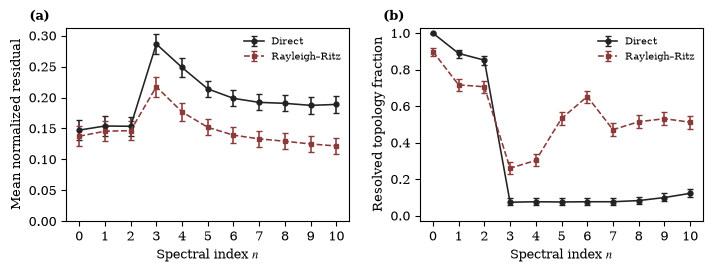

Saved: /home/clouduser/psi_jepa_project/psi_Jepa_V08/results/02_figures/spectral_tension_true_jepa_full_593bf82a_0d182910.png


In [8]:
plt.rcParams.update({'font.family':'serif','mathtext.fontset':'stix','font.size':9})
fig, axes = plt.subplots(1, 2, figsize=(7.2,2.8), sharex=True)
for route, color, marker, style, label in [('direct','#222222','o','-','Direct'),('rr','#8b3a3a','s','--','Rayleigh–Ritz')]:
    x = summary[summary.route.eq(route)]
    axes[0].errorbar(x.n,x.mean_residual,yerr=x.residual_ci95,color=color,marker=marker,ms=3.5,lw=1.15,capsize=2,ls=style,label=label)
    error = np.vstack([x.topology_fraction-x.topology_ci95_low,x.topology_ci95_high-x.topology_fraction])
    axes[1].errorbar(x.n,x.topology_fraction,yerr=error,color=color,marker=marker,ms=3.5,lw=1.15,capsize=2,ls=style,label=label)
axes[0].set(xlabel=r'Spectral index $n$',ylabel='Mean normalized residual',xticks=range(11),ylim=(0,None))
axes[1].set(xlabel=r'Spectral index $n$',ylabel='Resolved topology fraction',xticks=range(11),ylim=(-0.03,1.03))
for tag, ax in zip(('(a)','(b)'),axes):
    ax.grid(False); ax.text(-0.13,1.04,tag,transform=ax.transAxes,fontweight='bold'); ax.legend(frameon=False,fontsize=7)
fig.tight_layout(w_pad=1.8)
fig.savefig(FIGURE,dpi=300,bbox_inches='tight')
plt.show()
print('Saved:',FIGURE)
